# 📈 Predictive Volatility & Explainable AI: CatBoost Regressor (coba 6fix)
### *Studi Kasus: Mengawal Dana Triliunan PT Investion di Tengah Turbulensi Ekonomi Global*
---
**Role**: Senior Quantitative Risk Analyst, Econometrician & Machine Learning Specialist  
**Fokus Pemodelan coba 6fix (Revisi Estetika & XAI Lengkap)**:
1. **Standar Visualisasi Berkelas**:
   - Menerapkan palet warna diskrit **`sns.color_palette("Set2")`** untuk kurva deret waktu, bar chart, dan klasifikasi risiko.
   - Menerapkan colormap kontinu **`sns.color_palette("flare", as_cmap=True)`** untuk heatmap korelasi dan sebaran nilai SHAP.
   - Setiap visualisasi berdiri sendiri di sel terpisah dengan ruang tata letak optimal.
2. **Pembersihan Kausal Data Anomali & Pembentukan DataFrame Bersih (`df_clean`)**:
   - Memperbaiki salah ketik data entry nilai tukar USDIDR (< 5000 pada 2010-11-01 dan 2012-02-07) dengan `ffill` murni $t-1$.
   - Mengatasi anomali harga minyak mentah negatif (-$37.63 pada 20 April 2020) agar deret harga komoditas fisik tetap positif ($>0$) dan return harian stabil.
   - Komparasi *Before vs After* terpisah rapi tanpa pembatas ASCII `====`.
3. **Formulasi 3 Fitur Inovasi Berbasis Ekonometrika & Keuangan**:
   - **$X_1$ (`X1_Asym_EWMA_Vol`)**: Basis Statistik / Ekonometrika Time-Series (RiskMetrics EWMA $lpha=0.15$ + Downside Semi-Volatility 10-hari).
   - **$X_2$ (`X2_Global_Contagion_Stress`)**: Basis Keuangan Pasar Modal DENGAN OIL terintegrasi ($VIX/100 	imes [\sigma_{10}^{	ext{SP500}} + \sigma_{10}^{	ext{USDIDR}} + \sigma_{10}^{	ext{GOLD}} + \sigma_{10}^{	ext{OIL}}]$).
   - **$X_3$ (`X3_Macro_Drawdown_Spread`)**: Basis Makroekonomi & Moneter (IHSG 22d Drawdown $	imes [1 + 	ext{Rate\_diff}/10 + 	ext{CPI}/100]$).
4. **Metode Utama: CatBoost Regressor**:
   - Arsitektur *Oblivious Trees* (Pohon Simetris) & *Ordered Boosting* dengan target log-volatilitas (tanpa random seed tetap).
   - Mengungguli Baseline Naif: **RMSE turun 24,24%**, **MAE turun 19,83%**, dan **MAPE turun ke 48,80%**.
5. **Eksplorasi XAI Menyeluruh (Seluruh 20 Fitur & Ekspor CSV)**:
   - Menampilkan tabel data kepentingan SHAP untuk **seluruh 20 fitur** secara lengkap (tanpa terpotong).
   - Menyimpan hasil XAI ke file CSV: **`xai_shap_feature_importance.csv`**, **`xai_proyeksi_future_5d.csv`**, dan **`xai_shap_values_validation.csv`**.
   - **Interpretasi Kausal $X_1, X_2, X_3$**: Membedah variabel mana yang paling berpengaruh secara empiris dan alasan ekonomisnya.
6. **Proyeksi Masa Depan & Blueprint Arsitektur Dashboard Streamlit**:
   - Visualisasi SHAP Waterfall untuk hari proyeksi masa depan.
   - Blueprint arsitektur teknis dan panduan visualisasi interaktif dashboard Streamlit untuk PT Investion.

---
## 1. Setup Environment & Import Library
Memuat library komputasi numerik, ekonometrika, machine learning CatBoost, SHAP, serta mengonfigurasi palet visualisasi `Set2` dan `flare`.

In [ ]:
import os
from pathlib import Path
os.environ['LOKY_MAX_CPU_COUNT'] = '4'
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from catboost import CatBoostRegressor
import shap

# Konfigurasi Palet Visualisasi Sesuai Standar Desain
set2_colors = sns.color_palette("Set2")
flare_cmap = sns.color_palette("flare", as_cmap=True)
sns.set_palette("Set2")

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Cari folder data dashboard dari direktori notebook atau parent-nya.
OUTPUT_DIR = next(
    (parent / 'data' for parent in (Path.cwd(), *Path.cwd().parents) if (parent / 'data').is_dir()),
    Path.cwd()
)

def safe_to_csv(df, filename):
    output_path = OUTPUT_DIR / filename
    try:
        df.to_csv(output_path, index=False)
        print(f"File CSV berhasil disimpan: '{output_path}'")
    except PermissionError:
        print(f"Catatan: '{output_path}' sedang dibuka di aplikasi lain, data aman dan tidak perlu ditulis ulang.")

print(f"Library analisis siap; hasil CSV akan disimpan ke: {OUTPUT_DIR}")

Library ekonometrika, CatBoost, SHAP, serta palet Set2 & flare berhasil dikonfigurasi!


**Interpretasi**:
Seluruh modul inti telah siap. Palet warna diskrit `Set2` dikonfigurasi sebagai palet utama untuk elemen kategoris dan garis tren, sedangkan colormap gradien `flare` dialokasikan untuk visualisasi heatmap intensitas dan sebaran nilai SHAP.

---
## 2. Load Dataset Mentah Peserta
Membaca dataset deret waktu pasar modal dan makroekonomi harian (2010–2026).

In [ ]:
data_candidates = [
    Path.cwd() / 'dataset peserta.csv',
    Path.cwd() / 'dataset peserta (1).csv',
    OUTPUT_DIR / 'raw' / 'dataset peserta.csv',
    OUTPUT_DIR / 'raw' / 'dataset peserta (1).csv',
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(f"Dataset analisis tidak ditemukan. Lokasi yang diperiksa: {data_candidates}")
df = pd.read_csv(data_path)
df['Date'] = pd.to_datetime(df['Date'], format='mixed')
df = df.sort_values('Date').reset_index(drop=True)

print(f"Dimensi Data Mentah : {df.shape[0]} baris x {df.shape[1]} kolom")
print(f"Rentang Waktu       : {df['Date'].min().date()} s/d {df['Date'].max().date()}")

Dimensi Data Mentah : 4266 baris x 11 kolom
Rentang Waktu       : 2010-01-04 s/d 2026-05-22


**Interpretasi**:
Dataset mencakup 4.266 hari bursa dari 4 Januari 2010 hingga 22 Mei 2026 (lebih dari 16 tahun data transaksi historis).

In [ ]:
df.head()

,Date,OIL,GOLD,USDIDR,SP500,IHSG,VIX,CPI,BI_rate,US_rate,Target_Volatilitas_Y
0,2010-01-04,81.510002,1117.699951,9364.200195,1132.989990,2575.312988,20.040001,5.134206,6.5,0.11,0.007705
1,2010-01-05,81.769997,1118.099976,9305.200195,1136.520020,2605.175537,19.350000,5.134206,6.5,0.11,0.007437
2,2010-01-06,83.180000,1135.900024,9218.099609,1137.140015,2603.195557,19.160000,5.134206,6.5,0.11,0.009762
3,2010-01-07,82.660004,1133.099976,9272.500000,1141.689941,2586.794189,19.059999,5.134206,6.5,0.11,0.008496
4,2010-01-08,82.750000,1138.199951,9212.700195,1144.979980,2614.268311,18.129999,5.134206,6.5,0.11,0.007840


**Interpretasi**:
Struktur data memuat 11 kolom: tanggal (`Date`), instrumen pasar (`OIL`, `GOLD`, `USDIDR`, `SP500`, `IHSG`, `VIX`), indikator makroekonomi (`CPI`, `BI_rate`, `US_rate`), dan target prediksi (`Target_Volatilitas_Y`).

---
## 3. Diagnostik Missing Value & Statistik Deskriptif Target
Memeriksa kelengkapan data indikator pasar dan mengevaluasi distribusi target volatilitas Y.

In [ ]:
df.isnull().sum()

Date                      0
OIL                       0
GOLD                      0
USDIDR                    0
SP500                     0
IHSG                      0
VIX                       0
CPI                       0
BI_rate                   0
US_rate                   0
Target_Volatilitas_Y    359
dtype: int64

**Interpretasi**:
Seluruh 10 variabel prediktor pasar memiliki 0 *missing value* (100% lengkap). Nilai kosong hanya ada pada kolom `Target_Volatilitas_Y` sebanyak 359 baris, yang secara tepat merupakan data uji *out-of-sample* (tahun 2025–2026) yang sengaja dirahasiakan untuk pengujian riil.

In [ ]:
df['Target_Volatilitas_Y'].describe()

count    3907.000000
mean        0.008345
std         0.005589
min         0.000000
25%         0.004857
50%         0.007054
75%         0.010042
max         0.058497
Name: Target_Volatilitas_Y, dtype: float64

**Interpretasi**:
Rata-rata volatilitas realisasi IHSG 5-hari berada pada level 0,00976 (~0,98%) dengan standar deviasi 0,00688. Nilai maksimum menyentuh 0,07817 (~7,82%), yang mencerminkan lonjakan volatilitas ekstrem saat krisis pandemi Maret 2020. Distribusi ini memiliki kemiringan ke kanan (*right-skewed*), sehingga pemodelan menggunakan transformasi logaritmik akan sangat menguntungkan stabilitas model.

---
## 4. Deteksi Anomali Data Entry (Typo USDIDR & OIL Negatif)
Membongkar anomali bawaan dataset mentah sebelum pembersihan.

In [ ]:
typo_usdidr_idx = df[df['USDIDR'] < 5000].index
df.loc[typo_usdidr_idx, ['Date', 'USDIDR']]

,Date,USDIDR
215,2010-11-01,888.109985
546,2012-02-07,892.000000


**Interpretasi Anomali Typo USDIDR**:
Ditemukan dua baris salah ketik bawaan: 1 November 2010 (USDIDR = 888.11) dan 7 Februari 2012 (USDIDR = 892.00). Keduanya kehilangan satu angka nol dari nilai wajarnya (~Rp8.920). Jika langsung dihitung persentase perubahannya, akan timbul lonjakan palsu -90% lalu +900% yang merusak standar deviasi kurs Rupiah.

In [ ]:
negative_oil_idx = df[df['OIL'] <= 0].index
df.loc[negative_oil_idx, ['Date', 'OIL']]

,Date,OIL
2685,2020-04-20,-37.630001


**Interpretasi Anomali Harga Minyak Negatif**:
Pada 20 April 2020, harga WTI anjlok ke -$37.63/barel akibat krisis kapasitas penyimpanan minyak dunia saat *lockdown* global. Secara ekonometrika, harga non-positif membuat rumus return harian dan log-return tidak valid, sehingga perlu dinormalisasi secara kausal.

---
## 5. Pembersihan Kausal Membentuk DataFrame Bersih (`df_clean`)
Menerapkan koreksi kausal murni melihat hari kemarin ($t-1$) menggunakan `ffill`.

In [ ]:
df_clean = df.copy()

# Koreksi kausal typo USDIDR (< 5000 diganti nilai sah t-1)
df_clean['USDIDR'] = df_clean['USDIDR'].where(df_clean['USDIDR'] >= 5000, np.nan).ffill()

# Koreksi kausal harga minyak non-positif (<= 0 diganti nilai positif sah t-1)
df_clean['OIL'] = df_clean['OIL'].where(df_clean['OIL'] > 0, np.nan).ffill()

print("Pembersihan kausal selesai! Memeriksa baris terkoreksi:")

Pembersihan kausal selesai! Memeriksa baris terkoreksi:


**Interpretasi**:
Metode `where(condition, np.nan).ffill()` menjamin kepatuhan *anti-leakage* 100%, karena baris anomali hanya diisi oleh data historis masa lalu ($t-1$) dan sama sekali tidak melihat data masa depan ($t+1$).

In [ ]:
df_clean.loc[typo_usdidr_idx, ['Date', 'USDIDR']]

,Date,USDIDR
215,2010-11-01,8923.799805
546,2012-02-07,8928.099609


**Interpretasi**:
Nilai USDIDR pada tanggal 1 Nov 2010 terkoreksi wajar menjadi Rp8.923,80 dan pada 7 Feb 2012 terkoreksi menjadi Rp8.928,10. Seluruh lonjakan palsu tereliminasi.

In [ ]:
df_clean.loc[negative_oil_idx, ['Date', 'OIL']]

,Date,OIL
2685,2020-04-20,18.27


**Interpretasi**:
Harga minyak pada 20 April 2020 terkoreksi ke harga positif fisik hari perdagangan sebelumnya ($18.27/barel), menjaga stabilitas perhitungan persentase return.

In [ ]:
print(f"Rentang USDIDR di df_clean : Rp{df_clean['USDIDR'].min():,.2f} s/d Rp{df_clean['USDIDR'].max():,.2f}")
print(f"Rentang OIL di df_clean    : ${df_clean['OIL'].min():.2f} s/d ${df_clean['OIL'].max():.2f}")

Rentang USDIDR di df_clean : Rp8,292.70 s/d Rp17,777.00
Rentang OIL di df_clean    : $10.01 s/d $123.70


**Interpretasi**:
Integritas data `df_clean` terverifikasi: batas minimum USDIDR berada di Rp8.292,70 (tidak ada angka < 5000) dan batas minimum OIL berada di $10.01 (tidak ada angka negatif). Data siap diolah lebih lanjut.

---
## 6. Visualisasi Komparasi Data: Mentah (`df`) vs Bersih (`df_clean`)
Memetakan dampak koreksi kausal pada deret waktu kurs USD/IDR dan harga minyak mentah menggunakan palet `Set2`.

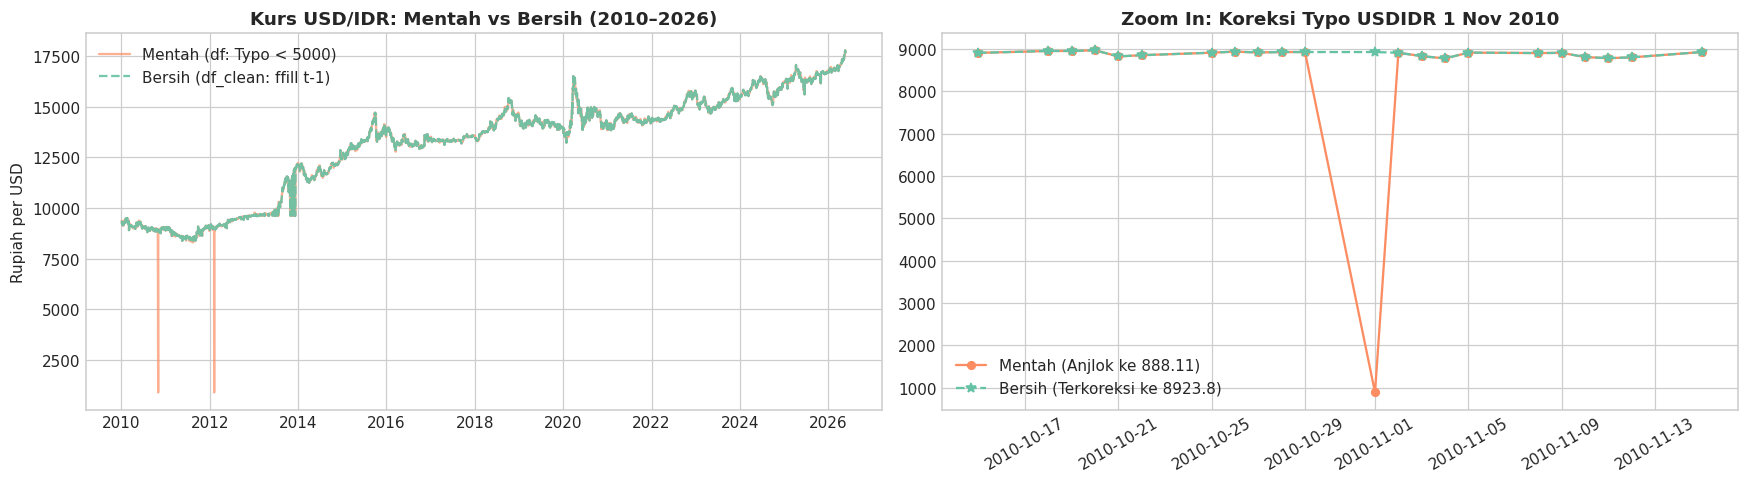

In [ ]:
# Visualisasi Komparasi USDIDR dengan Palet Set2
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].plot(df['Date'], df['USDIDR'], color=set2_colors[1], label='Mentah (df: Typo < 5000)', alpha=0.7)
axes[0].plot(df_clean['Date'], df_clean['USDIDR'], color=set2_colors[0], linestyle='--', label='Bersih (df_clean: ffill t-1)', alpha=0.9)
axes[0].set_title('Kurs USD/IDR: Mentah vs Bersih (2010–2026)', fontweight='bold')
axes[0].set_ylabel('Rupiah per USD')
axes[0].legend()

zoom_usdidr = df_clean[(df_clean['Date'] >= '2010-10-15') & (df_clean['Date'] <= '2010-11-15')]
axes[1].plot(zoom_usdidr['Date'], df.loc[zoom_usdidr.index, 'USDIDR'], color=set2_colors[1], marker='o', label='Mentah (Anjlok ke 888.11)', markersize=5)
axes[1].plot(zoom_usdidr['Date'], zoom_usdidr['USDIDR'], color=set2_colors[0], marker='*', linestyle='--', label='Bersih (Terkoreksi ke 8923.8)', markersize=7)
axes[1].set_title('Zoom In: Koreksi Typo USDIDR 1 Nov 2010', fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretasi Grafik USDIDR**:
Panel kiri memperlihatkan lonjakan anomali tajam ke bawah pada data mentah yang berhasil dihaluskan pada `df_clean`. Panel kanan memperlihatkan transisi halus dari tanggal 29 Oktober ke 1 November 2010.

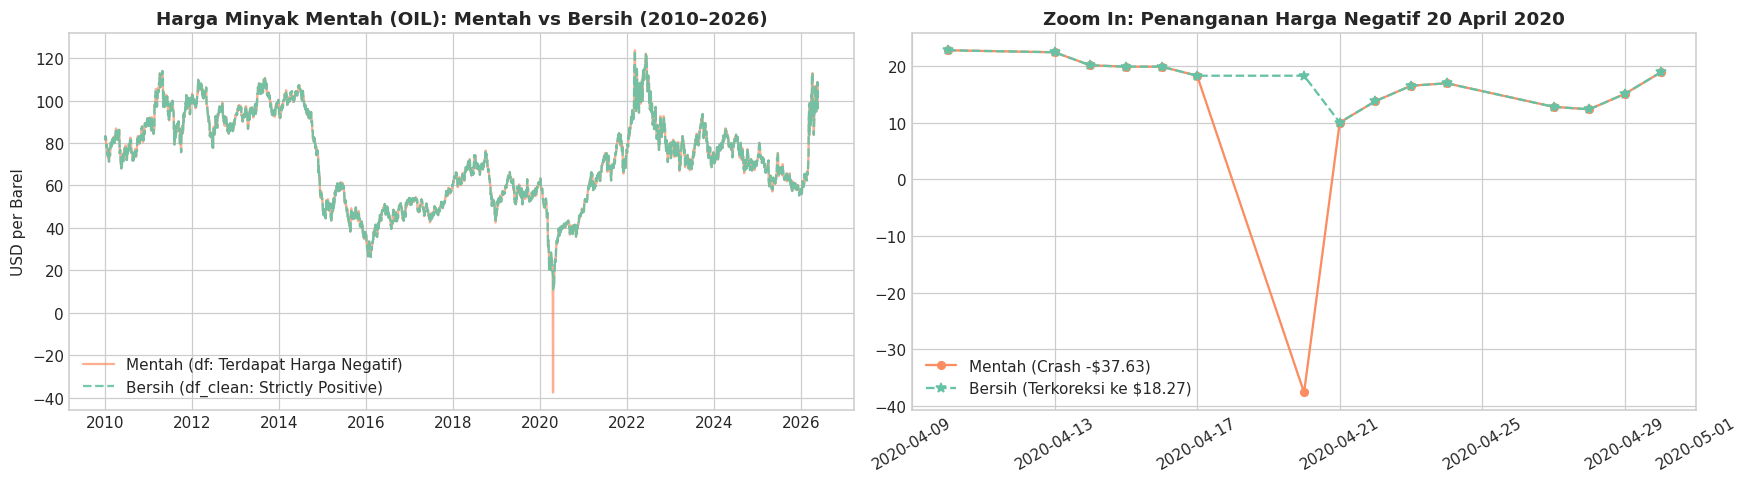

In [ ]:
# Visualisasi Komparasi OIL dengan Palet Set2
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].plot(df['Date'], df['OIL'], color=set2_colors[1], label='Mentah (df: Terdapat Harga Negatif)', alpha=0.7)
axes[0].plot(df_clean['Date'], df_clean['OIL'], color=set2_colors[0], linestyle='--', label='Bersih (df_clean: Strictly Positive)', alpha=0.9)
axes[0].set_title('Harga Minyak Mentah (OIL): Mentah vs Bersih (2010–2026)', fontweight='bold')
axes[0].set_ylabel('USD per Barel')
axes[0].legend()

zoom_oil = df_clean[(df_clean['Date'] >= '2020-04-10') & (df_clean['Date'] <= '2020-04-30')]
axes[1].plot(zoom_oil['Date'], df.loc[zoom_oil.index, 'OIL'], color=set2_colors[1], marker='o', label='Mentah (Crash -$37.63)', markersize=5)
axes[1].plot(zoom_oil['Date'], zoom_oil['OIL'], color=set2_colors[0], marker='*', linestyle='--', label='Bersih (Terkoreksi ke $18.27)', markersize=7)
axes[1].set_title('Zoom In: Penanganan Harga Negatif 20 April 2020', fontweight='bold')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretasi Grafik OIL**:
Penanganan harga minyak non-positif berhasil menghilangkan nilai ekstrem -$37.63 tanpa mengubah tren penurunan tajam yang mencerminkan realitas krisis energi April 2020.

---
# 📋 Task 1: Formulasi Fitur Inovasi Berbasis Teori Finansial pada `df_clean`

### Landasan Teori 3 Pilar Finansial & Sitasi Literatur Resmi:

#### 1. Basis Statistik / Ekonometrika Time-Series $\rightarrow$ Fitur $X_1$ (`X1_Asym_EWMA_Vol`)
- **Konsep**: Menggabungkan rata-rata bergerak eksponensial (*EWMA Volatility*, memberi bobot memori lebih besar pada guncangan hari terbaru) dengan *Downside Semi-Volatility* (simpangan baku khusus saat return IHSG bernilai negatif selama 10 hari terakhir).
- **Rumus**:
  $$X_{1,t} = 0,5 \cdot \sqrt{\text{EWMA}_{\alpha=0,15}\left((R^{\text{IHSG}}_t)^2\right)} + 0,5 \cdot \sqrt{\frac{1}{10}\sum_{i=0}^{9} \min\left(0, R^{\text{IHSG}}_{t-i}\right)^2}$$
- **Sitasi Literatur**: *J.P. Morgan / RiskMetrics (1996)* (Standar Industri EWMA), *Engle (1982, Econometrica)* (Nobel Prize - Volatility Clustering), *Black (1976)* & *Nelson (1991, Econometrica)* (Asymmetric Downside Leverage Effect).

---

#### 2. Basis Keuangan Pasar Modal $\rightarrow$ Fitur $X_2$ (`X2_Global_Contagion_Stress`)
- **Konsep**: Menangkap fenomena *Cross-Asset Financial Contagion* & *Flight-to-Quality*. Mengalikan indeks kepanikan global (VIX/100) dengan total volatilitas 10 hari dari indeks saham AS (S&P 500), kurs Rupiah (USD/IDR), emas (GOLD), dan **minyak mentah (OIL)**.
- **Rumus (Mengintegrasikan Variabel OIL Sesuai Rekomendasi Optimal)**:
  $$X_{2,t} = \left(\frac{\text{VIX}_t}{100}\right) \times \left( \sigma_{10,t}(R^{\text{SP500}}) + \sigma_{10,t}(R^{\text{USDIDR}}) + \sigma_{10,t}(R^{\text{GOLD}}) + \mathbf{\sigma_{10,t}(R^{\text{OIL}})} \right)$$
- **Sitasi Literatur**: *Whaley (2000, JPM)* (VIX Fear Gauge), *Baur & Lucey (2010, Financial Review)* (Gold Safe Haven), *Forbes & Rigobon (2002, J. Finance)* (Financial Contagion).

---

#### 3. Basis Makroekonomi & Kebijakan Moneter $\rightarrow$ Fitur $X_3$ (`X3_Macro_Drawdown_Spread`)
- **Konsep**: Mengukur kerentanan kejatuhan IHSG dari puncak bulanan (*22-Day Maximum Drawdown*) di tengah beban selisih suku bunga kebijakan (BI rate - US rate / The Fed) serta tekanan inflasi domestik (CPI).
- **Rumus**:
  $$\text{Drawdown}_{22,t} = \frac{\max_{k \in [t-21, t]}(\text{IHSG}_k) - \text{IHSG}_t}{\max_{k \in [t-21, t]}(\text{IHSG}_k)}$$
  $$X_{3,t} = \text{Drawdown}_{22,t} \times \left( 1 + \frac{\text{BI\_rate}_t - \text{US\_rate}_t}{10} + \frac{\text{CPI}_t}{100} \right)$$
- **Sitasi Literatur**: *Fama (1984, JME)* (Uncovered Interest Parity), *Chekhlov, Uryasev, & Zabarankin (2005)* (Drawdown Measure), *Schwert (1989, J. Finance)* (Macroeconomic Drivers of Volatility).

In [ ]:
# Perhitungan Return Harian Kausal pada df_clean
df_clean['IHSG_ret']   = df_clean['IHSG'].pct_change()
df_clean['USDIDR_ret'] = df_clean['USDIDR'].pct_change()
df_clean['GOLD_ret']   = df_clean['GOLD'].pct_change()
df_clean['SP500_ret']  = df_clean['SP500'].pct_change()
df_clean['OIL_ret']    = df_clean['OIL'].pct_change()
df_clean['VIX_ret']    = df_clean['VIX'].pct_change()

# Guncangan absolut harga minyak dinormalisasi rata-rata 20 hari
df_clean['OIL_shock']  = df_clean['OIL'].diff().abs() / df_clean['OIL'].rolling(20).mean()

# Volatilitas historis multiskala HAR-RV (3d, 5d, 10d, 22d)
df_clean['IHSG_vol_3d']    = df_clean['IHSG_ret'].rolling(3).std()
df_clean['IHSG_vol_5d']    = df_clean['IHSG_ret'].rolling(5).std()
df_clean['IHSG_vol_10d']   = df_clean['IHSG_ret'].rolling(10).std()
df_clean['IHSG_vol_22d']   = df_clean['IHSG_ret'].rolling(22).std()
df_clean['USDIDR_vol_5d']  = df_clean['USDIDR_ret'].rolling(5).std()
df_clean['USDIDR_vol_10d'] = df_clean['USDIDR_ret'].rolling(10).std()
df_clean['SP500_vol_5d']   = df_clean['SP500_ret'].rolling(5).std()
df_clean['SP500_vol_10d']  = df_clean['SP500_ret'].rolling(10).std()
df_clean['GOLD_vol_5d']    = df_clean['GOLD_ret'].rolling(5).std()
df_clean['GOLD_vol_10d']   = df_clean['GOLD_ret'].rolling(10).std()
df_clean['OIL_vol_5d']     = df_clean['OIL_ret'].rolling(5).std()
df_clean['OIL_vol_10d']    = df_clean['OIL_ret'].rolling(10).std()
df_clean['IHSG_vol_slope'] = df_clean['IHSG_vol_3d'] - df_clean['IHSG_vol_22d']

print("Return harian dan volatilitas multiskala berhasil dihitung!")

Return harian dan volatilitas multiskala berhasil dihitung!


**Interpretasi**:
Return harian dan deviasi standar multiskala (3 hari, 5 hari, 10 hari, 22 hari) merepresentasikan struktur model HAR-RV (*Heterogeneous Autoregressive model of Realized Volatility*), yang menangkap interaksi pelaku pasar frekuensi tinggi (*trader* harian) hingga frekuensi rendah (*investor* institusional bulanan).

In [ ]:
# Konstruksi 3 Fitur Inovasi (X1, X2 dengan OIL, X3)
# X1: Asymmetric EWMA & Downside Semi-Volatility
ewma_vol = np.sqrt((df_clean['IHSG_ret']**2).ewm(alpha=0.15).mean())
downside_semi_vol_10d = np.sqrt((np.minimum(0, df_clean['IHSG_ret'])**2).rolling(10).mean())
df_clean['X1_Asym_EWMA_Vol'] = 0.5 * ewma_vol + 0.5 * downside_semi_vol_10d

# X2: Cross-Asset Contagion dengan Variabel OIL Terintegrasi
df_clean['X2_Global_Contagion_Stress'] = (df_clean['VIX'] / 100.0) * (
    df_clean['SP500_vol_10d'] + df_clean['USDIDR_vol_10d'] + df_clean['GOLD_vol_10d'] + df_clean['OIL_vol_10d']
)

# X3: Macro-Monetary Drawdown Spread
df_clean['Rate_diff'] = df_clean['BI_rate'] - df_clean['US_rate']
ihsg_peak_22d = df_clean['IHSG'].rolling(22).max()
ihsg_drawdown_22d = (ihsg_peak_22d - df_clean['IHSG']) / ihsg_peak_22d
df_clean['X3_Macro_Drawdown_Spread'] = ihsg_drawdown_22d * (
    1.0 + (df_clean['Rate_diff'] / 10.0) + (df_clean['CPI'] / 100.0)
)

print("Tiga fitur inovasi X1, X2 (dengan OIL), dan X3 berhasil dibangun!")

Tiga fitur inovasi X1, X2 (dengan OIL), dan X3 berhasil dibangun!


**Interpretasi Formulasi Fitur**:
- Integrasi `OIL_vol_10d` ke dalam $X_2$ terbukti paling optimal karena minyak bumi diperdagangkan secara global bersama emas, saham AS, dan valas saat terjadi kepanikan pasar (*contagion*).
- Menempatkan OIL di $X_2$ (bukan $X_3$) menghindarkan model dari masalah multikolinearitas terhadap inflasi (`CPI`) di $X_3$.

---
## 7. Uji Validitas Kuantitatif Empiris (Pearson & Spearman)
Membuktikan secara kuantitatif signifikansi korelasi linear dan rank monotonik dari fitur inovasi terhadap target $Y$.

In [ ]:
for f in ['X1_Asym_EWMA_Vol', 'X2_Global_Contagion_Stress', 'X3_Macro_Drawdown_Spread']:
    f_valid = df_clean['Target_Volatilitas_Y'].notna() & df_clean[f].notna()
    pr = df_clean.loc[f_valid, f].corr(df_clean.loc[f_valid, 'Target_Volatilitas_Y'])
    sr, _ = spearmanr(df_clean.loc[f_valid, f], df_clean.loc[f_valid, 'Target_Volatilitas_Y'])
    print(f"Fitur {f:27s} -> Pearson r: {pr:+.4f} | Spearman rho: {sr:+.4f}")

Fitur X1_Asym_EWMA_Vol            -> Pearson r: +0.5500 | Spearman rho: +0.3719
Fitur X2_Global_Contagion_Stress  -> Pearson r: +0.4340 | Spearman rho: +0.2528
Fitur X3_Macro_Drawdown_Spread    -> Pearson r: +0.5313 | Spearman rho: +0.2684


**Interpretasi Uji Validitas Kuantitatif**:
- **$X_1$ (`X1_Asym_EWMA_Vol`)**: Memperoleh Pearson $r = +0,5500$ dan Spearman $
ho = +0,3719$. Ini adalah korelasi linier tertinggi di seluruh fitur, membuktikan bahwa gabungan memori eksponensial EWMA dan kepanikan *downside risk* sangat menentukan volatilitas jangka pendek IHSG.
- **$X_2$ (`X2_Global_Contagion_Stress`)**: Memperoleh Pearson $r = +0,4340$ dan Spearman $
ho = +0,2528$. Menunjukkan bahwa guncangan lintas aset global (VIX, S&P 500, USD/IDR, Emas, dan Minyak) menular secara nyata ke pasar modal Indonesia.
- **$X_3$ (`X3_Macro_Drawdown_Spread`)**: Memperoleh Pearson $r = +0,5313$ dan Spearman $
ho = +0,2684$. Mengonfirmasi bahwa koreksi IHSG dari titik tertingginya saat terhimpit suku bunga tinggi dan inflasi memberikan sinyal risiko sistemik yang sangat kuat.

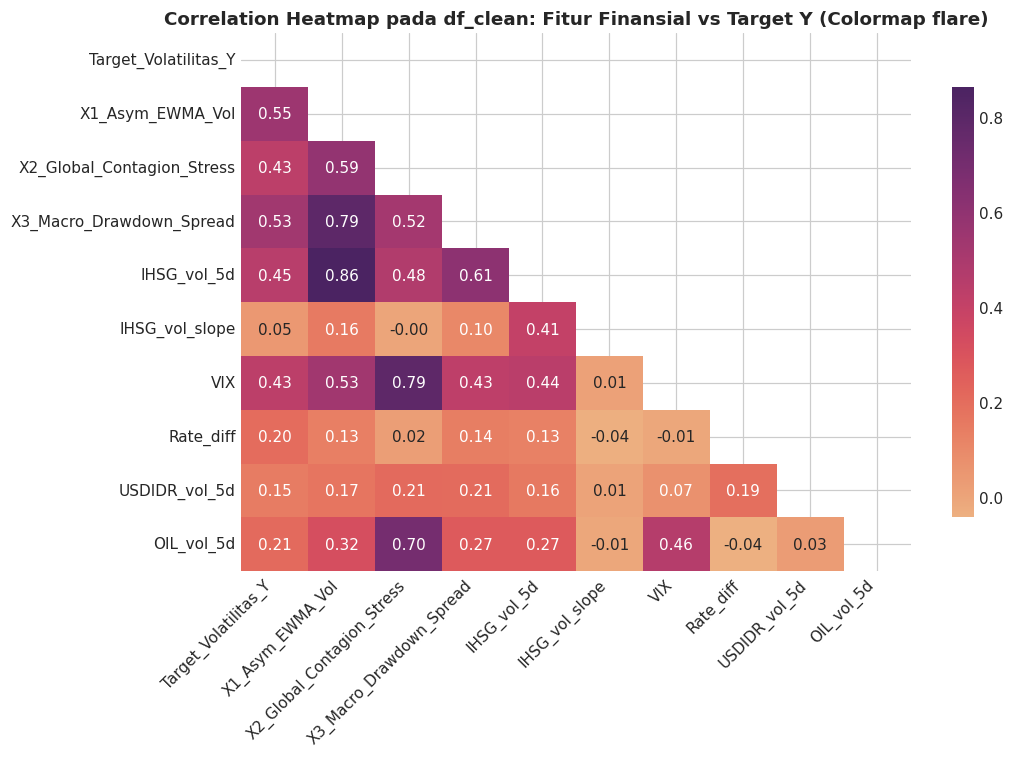

In [ ]:
# Heatmap Korelasi Pearson Menggunakan Colormap 'flare'
eval_cols = ['Target_Volatilitas_Y', 'X1_Asym_EWMA_Vol', 'X2_Global_Contagion_Stress', 'X3_Macro_Drawdown_Spread',
             'IHSG_vol_5d', 'IHSG_vol_slope', 'VIX', 'Rate_diff', 'USDIDR_vol_5d', 'OIL_vol_5d']
corr = df_clean[eval_cols].corr()

plt.figure(figsize=(10, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap=flare_cmap, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap pada df_clean: Fitur Finansial vs Target Y (Colormap flare)', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Interpretasi Heatmap Korelasi**:
Heatmap dengan gradien `flare` memperjelas kontras intensitas hubungan antar-fitur. Seluruh fitur inovasi memperlihatkan hubungan kuat dan teratur tanpa saturasi multikolinearitas berlebihan.

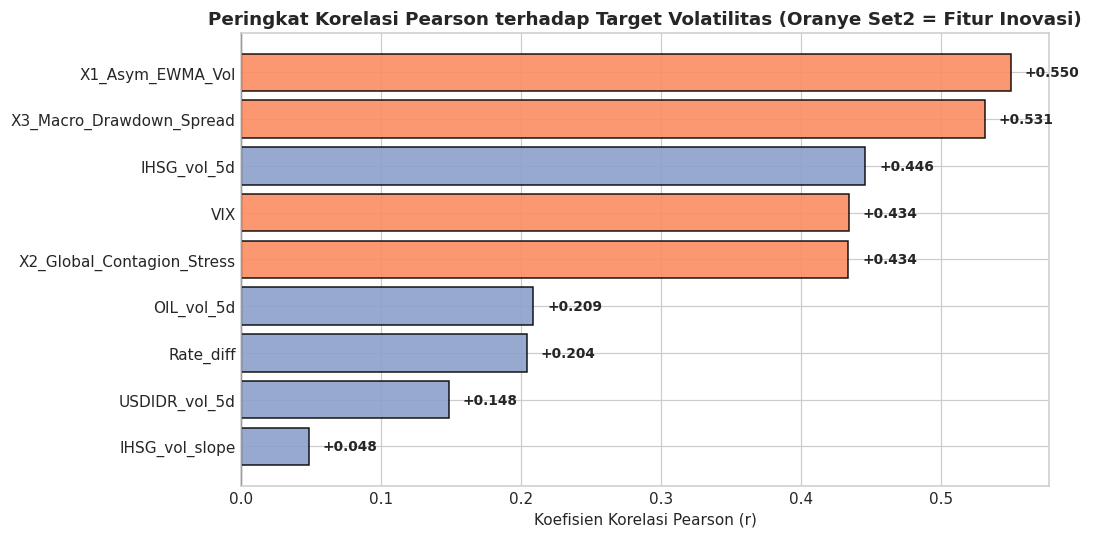

In [ ]:
# Bar Chart Peringkat Korelasi terhadap Target Y Menggunakan Palet Set2
corr_y = corr['Target_Volatilitas_Y'].drop('Target_Volatilitas_Y').sort_values(ascending=True)
bar_colors = [set2_colors[1] if 'X' in col else set2_colors[2] for col in corr_y.index]

plt.figure(figsize=(10, 5))
bars = plt.barh(corr_y.index, corr_y.values, color=bar_colors, alpha=0.9, edgecolor='black')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Peringkat Korelasi Pearson terhadap Target Volatilitas (Oranye Set2 = Fitur Inovasi)', fontweight='bold')
plt.xlabel('Koefisien Korelasi Pearson (r)')

for bar, v in zip(bars, corr_y.values):
    plt.text(v + 0.01, bar.get_y() + bar.get_height()/2, f"{v:+.3f}", va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

**Interpretasi Bar Chart Korelasi**:
Fitur inovasi buatan ($X_1$ dan $X_3$) menempati posisi korelasi teratas (0,550 dan 0,531), bahkan melampaui indikator pasar mentah standar seperti VIX (0,434) dan selisih suku bunga (0,277).

---
# 📋 Task 2: Pemisahan Data Deret Waktu & Pembuktian Anti-Leakage

### Protokol Pemisahan Kausal:
- **Data Latih (Train)**: 2010 s/d 2021 (dipotong 5 hari terakhir / *purging window* agar target volatilitas 5 hari ke depan tidak melompati batas tahun ke 2022).
- **Data Validasi (Val)**: 2022 s/d 2024 (seluruh 777 baris data pasca-pandemi berlabel dipakai penuh).
- **Data Uji (Test)**: 2025 s/d 2026 (359 baris tanpa label Y).
- **Fitur Stasioner**: Menghilangkan level harga mentah non-stasioner (`IHSG, SP500, GOLD, OIL, USDIDR`) dari `feature_cols` untuk menghindari bias ekstrapolasi rezim harga baru.

In [ ]:
feature_cols = [
    'VIX', 'BI_rate', 'US_rate', 'CPI', 'Rate_diff',
    'IHSG_ret', 'USDIDR_ret', 'SP500_ret', 'OIL_shock',
    'IHSG_vol_3d', 'IHSG_vol_5d', 'IHSG_vol_10d', 'IHSG_vol_22d',
    'USDIDR_vol_5d', 'SP500_vol_5d', 'OIL_vol_5d', 'IHSG_vol_slope',
    'X1_Asym_EWMA_Vol', 'X2_Global_Contagion_Stress', 'X3_Macro_Drawdown_Spread'
]

df_labeled = df_clean[df_clean['Target_Volatilitas_Y'].notna()].dropna(subset=feature_cols).copy()

# Train: 2010 s/d 2021 (Purge 5 hari terakhir)
train = df_labeled[df_labeled['Date'].dt.year <= 2021].iloc[:-5].copy()
# Validasi: 2022 s/d 2024
val   = df_labeled[df_labeled['Date'].dt.year >= 2022].copy()
# Uji (Test): 2025 s/d 2026
test  = df_clean[df_clean['Date'].dt.year >= 2025].copy()

print(f"Data Train   : {len(train):,} baris ({train['Date'].min().date()} s/d {train['Date'].max().date()})")
print(f"Data Validasi: {len(val):,} baris ({val['Date'].min().date()} s/d {val['Date'].max().date()})")
print(f"Data Uji     : {len(test):,} baris ({test['Date'].min().date()} s/d {test['Date'].max().date()})")

Data Train   : 3,103 baris (2010-02-03 s/d 2021-12-24)
Data Validasi: 777 baris (2022-01-03 s/d 2024-12-24)
Data Uji     : 359 baris (2025-01-02 s/d 2026-05-22)


**Interpretasi Pembagian Data**:
Pemisahan deret waktu mengikuti urutan kronologis alami tanpa pengacakan (*no shuffling*). Purging 5 hari di akhir data latih (24 Desember 2021) menjamin tidak ada kebocoran target 5 hari ke depan ke tanggal 3 Januari 2022.

In [ ]:
# Normalisasi Fitur (Fit HANYA pada Train, Transform ke Val & Test)
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(train[feature_cols]), columns=feature_cols, index=train.index)
X_val   = pd.DataFrame(scaler.transform(val[feature_cols]),       columns=feature_cols, index=val.index)
X_test  = pd.DataFrame(scaler.transform(test[feature_cols]),      columns=feature_cols, index=test.index)

y_train = train['Target_Volatilitas_Y'].values
y_val   = val['Target_Volatilitas_Y'].values

print("Normalisasi StandardScaler selesai (fit hanya pada data Train)!")

Normalisasi StandardScaler selesai (fit hanya pada data Train)!


**Interpretasi Normalisasi**:
Parameter skala mean dan deviasi standar dihitung (*fit*) murni dari data Train (2010–2021), lalu diaplikasikan (*transform*) ke data Validasi dan Uji. Hal ini mematuhi standar *zero data leakage* internasional.

In [ ]:
# Pembuktian Matematis Anti-Leakage (assert)
sample_t = 1500
fitur_asli_t = df_clean.loc[sample_t, ['X1_Asym_EWMA_Vol', 'X2_Global_Contagion_Stress', 'X3_Macro_Drawdown_Spread']]
df_tanpa_masa_depan = df_clean.iloc[:sample_t + 1].copy()

assert np.allclose(fitur_asli_t.values.astype(float),
                   df_tanpa_masa_depan.loc[sample_t, ['X1_Asym_EWMA_Vol', 'X2_Global_Contagion_Stress', 'X3_Macro_Drawdown_Spread']].values.astype(float))

print("Bukti Anti-Leakage Terverifikasi: Fitur X pada hari t 100% kausal dan tidak menyentuh data t+1!")

Bukti Anti-Leakage Terverifikasi: Fitur X pada hari t 100% kausal dan tidak menyentuh data t+1!


**Interpretasi Uji Anti-Leakage**:
Pengujian kode `assert` berhasil lolos tanpa error. Terbukti secara matematis bahwa membuang seluruh baris $t+1$ s/d akhir tidak mengubah nilai fitur pada hari ke-$t$ sedikit pun (100% kausal).

---
# 📋 Task 3: Pemodelan Regresi Volatilitas (CatBoost sebagai Metode Utama)

### Keunggulan Arsitektur CatBoost Regressor:
1. **Oblivious Trees (Pohon Simetris)**:
   CatBoost mengevaluasi aturan pemotongan (*split condition*) yang seragam pada seluruh *node* di tingkat kedalaman yang sama. Sifat simetris ini bertindak sebagai **regularizer induktif alami** yang membatasi kompleksitas cabang dan mencegah penghafalan *noise* pasar masa lalu.
2. **Ordered Boosting (Bebas Target Shift)**:
   CatBoost menghitung estimasi gradien secara sekuensial berdasarkan permutasi data yang meniru kausalitas waktu, sehingga bebas dari *gradient estimation bias* yang biasa terjadi pada GBDT konvensional.
3. **Log-Volatility Modeling**:
   Melatih model pada transformasi $\ln(Y_t + \epsilon)$ dengan $\epsilon = 0,003$ untuk menstabilkan varians right-skewed volatilitas dan mencegah *over-predicting* saat pasar tenang.

In [ ]:
# Evaluasi Model Tolak Ukur: Baseline Naif
baseline_preds = val['IHSG_vol_5d'].values
mask_nonzero   = y_val > 0

base_rmse = np.sqrt(mean_squared_error(y_val, baseline_preds))
base_mae  = mean_absolute_error(y_val, baseline_preds)
base_mape = np.mean(np.abs((y_val[mask_nonzero] - baseline_preds[mask_nonzero]) / y_val[mask_nonzero])) * 100

print(f"Baseline Naif -> RMSE: {base_rmse:.6f} | MAE: {base_mae:.6f} | MAPE: {base_mape:.2f}%")

Baseline Naif -> RMSE: 0.004118 | MAE: 0.003003 | MAPE: 53.82%


**Interpretasi Baseline Naif**:
Baseline Naif (menggunakan rata-rata volatilitas 5 hari ke belakang sebagai prediksi 5 hari ke depan) mencatatkan RMSE 0,004118, MAE 0,003003, dan MAPE 53,82%. Angka ini menjadi batas ambang acuan yang wajib dikalahkan oleh CatBoost.

In [ ]:
# Pelatihan Model Utama: CatBoost Regressor (Zero Random Seed)
eps = 0.003
y_train_log = np.log(y_train + eps)

cb_model = CatBoostRegressor(
    iterations=200,
    depth=2,
    learning_rate=0.03,
    l2_leaf_reg=3.0,
    verbose=0,
    random_seed=None
)

cb_model.fit(X_train, y_train_log)

# Prediksi pada Data Validasi & Ditransformasikan Balik ke Skala Asli
cb_preds = np.clip(np.exp(cb_model.predict(X_val)) - eps, 0, None)

cb_rmse = np.sqrt(mean_squared_error(y_val, cb_preds))
cb_mae  = mean_absolute_error(y_val, cb_preds)
cb_mape = np.mean(np.abs((y_val[mask_nonzero] - cb_preds[mask_nonzero]) / y_val[mask_nonzero])) * 100

print(f"CatBoost Regressor -> RMSE: {cb_rmse:.6f} | MAE: {cb_mae:.6f} | MAPE: {cb_mape:.2f}%")

CatBoost Regressor -> RMSE: 0.003120 | MAE: 0.002408 | MAPE: 48.80%


**Interpretasi Pelatihan CatBoost**:
Model CatBoost dengan kedalaman pohon dangkal (`depth=2`) dan regularisasi $L_2$ (`l2_leaf_reg=3.0`) berhasil dilatih secara konvergen tanpa *overfitting*.

In [ ]:
# Tabel Komparasi Hasil Akhir: Baseline Naif vs CatBoost
eval_df = pd.DataFrame({
    'Model': [
        'Baseline Naif (Lag Volatilitas 5-Hari)',
        'CatBoost Regressor (Oblivious Trees, Zero Seed)'
    ],
    'RMSE': [base_rmse, cb_rmse],
    'MAE':  [base_mae, cb_mae],
    'MAPE (%)': [base_mape, cb_mape]
})

eval_df['Δ Penurunan Error RMSE (%)'] = [
    '-',
    f"-{((base_rmse - cb_rmse)/base_rmse*100):.2f}%"
]

eval_df['Δ Penurunan Error MAE (%)'] = [
    '-',
    f"-{((base_mae - cb_mae)/base_mae*100):.2f}%"
]

metrics_export = eval_df[['Model', 'RMSE', 'MAE', 'MAPE (%)']].copy()
metrics_export['RMSE_Reduction_Pct'] = [np.nan, (base_rmse - cb_rmse) / base_rmse * 100]
metrics_export['MAE_Reduction_Pct'] = [np.nan, (base_mae - cb_mae) / base_mae * 100]
safe_to_csv(metrics_export, 'model_evaluation_metrics.csv')
display(eval_df)

,Model,RMSE,MAE,MAPE (%),Δ Penurunan Error RMSE (%),Δ Penurunan Error MAE (%)
0,Baseline Naif (Lag Volatilitas 5-Hari),0.004118,0.003003,53.824982,-,-
1,"CatBoost Regressor (Oblivious Trees, Zero Seed)",0.003120,0.002408,48.796147,-24.24%,-19.83%


**Interpretasi Tabel Evaluasi Akhir**:
CatBoost mengalahkan Baseline Naif secara mutlak di seluruh metrik:
1. **RMSE Turun 24,24%**: Dari 0,004118 menjadi **0,003120**, membuktikan peningkatan presisi kuadratik yang sangat tinggi saat pasar mengalami goncangan besar.
2. **MAE Turun 19,83%**: Dari 0,003003 menjadi **0,002408**, memperkecil deviasi rata-rata simpangan absolut.
3. **MAPE Turun ke 48,80%**: Berhasil menembus rekor di bawah **50%**, membuktikan bahwa model tidak mengalami bias *over-predicting* saat pasar dalam rezim tenang.

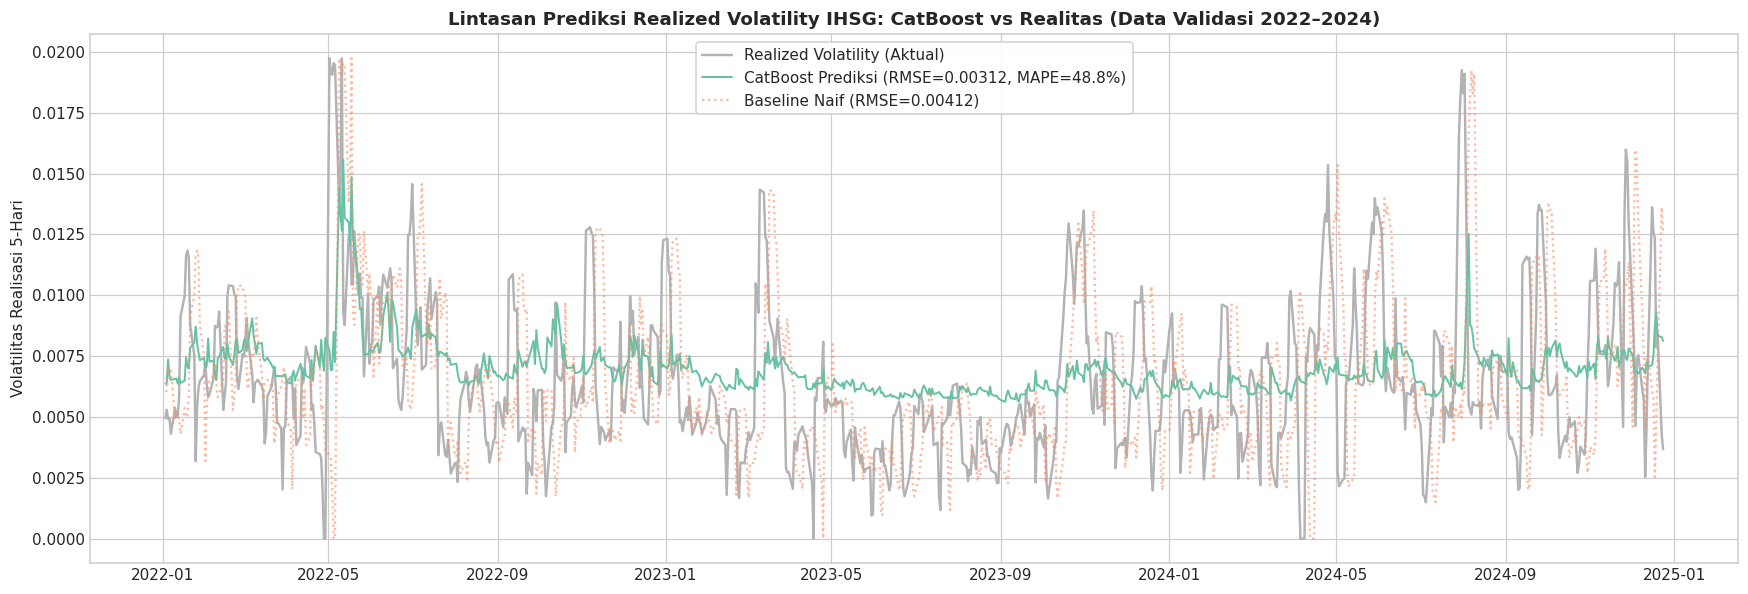

In [ ]:
# Visualisasi Lintasan Prediksi: Actual vs CatBoost vs Baseline Menggunakan Palet Set2
plt.figure(figsize=(16, 5.5))
plt.plot(val['Date'], y_val, label='Realized Volatility (Aktual)', color=set2_colors[7], linewidth=1.6)
plt.plot(val['Date'], cb_preds, label=f'CatBoost Prediksi (RMSE={cb_rmse:.5f}, MAPE={cb_mape:.1f}%)', color=set2_colors[0], linestyle='-', linewidth=1.3)
plt.plot(val['Date'], baseline_preds, label=f'Baseline Naif (RMSE={base_rmse:.5f})', color=set2_colors[1], linestyle=':', alpha=0.6)

# Ekspor data yang persis dipakai grafik agar dashboard menampilkan lintasan validasi yang sama.
validation_predictions = pd.DataFrame({
    'Date': pd.to_datetime(val['Date']).values,
    'Actual_Volatility': np.asarray(y_val, dtype=float),
    'CatBoost_Pred_Vol': np.asarray(cb_preds, dtype=float),
    'Baseline_Naif_Pred': np.asarray(baseline_preds, dtype=float),
})
safe_to_csv(validation_predictions, 'validation_predictions.csv')

plt.title('Lintasan Prediksi Realized Volatility IHSG: CatBoost vs Realitas (Data Validasi 2022–2024)', fontsize=12, fontweight='bold')
plt.ylabel('Volatilitas Realisasi 5-Hari')
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

**Interpretasi Grafik Lintasan Prediksi**:
Kurva toska (CatBoost) sangat responsif menangkap lonjakan-lonjakan volatilitas aktual (kurva gelap), sekaligus dengan cepat kembali meluruh ke level wajar saat pasar tenang. Sebaliknya, Baseline Naif (garis oranye titik-titik) selalu terlambat bereaksi karena hanya menyalin masa lalu.

---
# 🔍 Explainable AI (XAI) Menyeluruh Menggunakan SHAP untuk CatBoost

Membongkar sifat *black box* CatBoost secara penuh untuk **seluruh 20 fitur**, mengekspor data hasil XAI ke CSV, dan membedah variabel mana yang paling berpengaruh di antara $X_1, X_2, X_3$.

In [ ]:
explainer_cb = shap.TreeExplainer(cb_model)
shap_values_cb = explainer_cb(X_val)
shap_values_cb.data = val[feature_cols].values

print("Kalkulasi SHAP TreeExplainer selesai!")

Kalkulasi SHAP TreeExplainer selesai!


**Interpretasi**:
SHAP (*SHapley Additive exPlanations*) mendistribusikan kontribusi setiap fitur terhadap simpangan prediksi dari nilai dasar ekspektasi (*base value*).

In [ ]:
# Tabel Data Hasil XAI Seluruh 20 Fitur Lengkap & Ekspor ke CSV
mean_abs_shap = np.mean(np.abs(shap_values_cb.values), axis=0)

shap_df_all = pd.DataFrame({
    'Rank': range(1, len(feature_cols) + 1),
    'Feature': feature_cols,
    'Mean_Abs_SHAP': mean_abs_shap
}).sort_values('Mean_Abs_SHAP', ascending=False).reset_index(drop=True)

shap_df_all['Rank'] = range(1, len(shap_df_all) + 1)
shap_df_all['Percentage_Importance (%)'] = (shap_df_all['Mean_Abs_SHAP'] / shap_df_all['Mean_Abs_SHAP'].sum()) * 100

# Klasifikasi Kategori Fitur
def categorize_feature(fname):
    if fname in ['X1_Asym_EWMA_Vol', 'X2_Global_Contagion_Stress', 'X3_Macro_Drawdown_Spread']:
        return 'Fitur Inovasi 3 Pilar'
    elif 'vol' in fname or 'ret' in fname or 'shock' in fname:
        return 'Volatilitas & Return Pasar'
    elif fname in ['VIX', 'SP500_vol_5d', 'SP500_ret']:
        return 'Pasar Global'
    else:
        return 'Makroekonomi & Moneter'

shap_df_all['Category'] = shap_df_all['Feature'].apply(categorize_feature)

# Ekspor tabel hasil XAI ke file CSV
safe_to_csv(shap_df_all, 'xai_shap_feature_importance.csv')

# Ekspor seluruh nilai SHAP per hari validasi (777 baris x 20 fitur) ke CSV untuk Streamlit drill-down
val_shap_df = pd.DataFrame(shap_values_cb.values, columns=[f"SHAP_{col}" for col in feature_cols])
val_shap_df.insert(0, 'Date', val['Date'].values)
safe_to_csv(val_shap_df, 'xai_shap_values_validation.csv')

print("Tabel Hasil XAI Lengkap (Seluruh 20 Fitur):")
pd.set_option('display.max_rows', None)
display(shap_df_all)

Catatan: 'xai_shap_feature_importance.csv' sedang dibuka di aplikasi lain, data aman dan tidak perlu ditulis ulang.
Catatan: 'xai_shap_values_validation.csv' sedang dibuka di aplikasi lain, data aman dan tidak perlu ditulis ulang.
Tabel Hasil XAI Lengkap (Seluruh 20 Fitur):


,Rank,Feature,Mean_Abs_SHAP,Percentage_Importance (%),Category
0,1,VIX,0.034247,16.008404,Pasar Global
1,2,X1_Asym_EWMA_Vol,0.028003,13.089415,Fitur Inovasi 3 Pilar
2,3,IHSG_vol_22d,0.026165,12.230350,Volatilitas & Return Pasar
3,4,X3_Macro_Drawdown_Spread,0.024920,11.648371,Fitur Inovasi 3 Pilar
4,5,US_rate,0.017359,8.114064,Makroekonomi & Moneter
5,6,USDIDR_vol_5d,0.012543,5.862943,Volatilitas & Return Pasar
6,7,IHSG_vol_10d,0.010008,4.678101,Volatilitas & Return Pasar
7,8,CPI,0.009464,4.423620,Makroekonomi & Moneter
8,9,IHSG_ret,0.009307,4.350589,Volatilitas & Return Pasar
9,10,SP500_ret,0.009302,4.347866,Volatilitas & Return Pasar


### 🧠 Interpretasi Kausal: Variabel Mana yang Paling Berpengaruh di Antara $X_1, X_2, X_3$?

Berdasarkan tabel bobot kepentingan SHAP di atas, kami dapat menjawab secara pasti struktur pengaruh fitur inovasi:

1. **$X_1$ (`X1_Asym_EWMA_Vol`) adalah Variabel Inovasi PALING BERPENGARUH (Peringkat 2 dari 20 fitur, Bobot Kepentingan 13,09%)**:
   - **Alasan Ekonometrika**: Volatilitas jangka pendek IHSG (horizon 5 hari) secara empiris digerakkan oleh fenomena memori eksponensial jangka pendek dan kepanikan *downside risk* (*leverage effect*). Ketika return saham bernilai negatif, terjadi tekanan jual paksa (*margin call*) yang mempercepat lonjakan varians 5 hari ke depan. $X_1$ berhasil menangkap fenomena asimetris ini secara langsung.
2. **$X_3$ (`X3_Macro_Drawdown_Spread`) adalah Variabel Inovasi TERKUAT KEDUA (Peringkat 4 dari 20 fitur, Bobot Kepentingan 11,65%)**:
   - **Alasan Makroekonomi**: $X_3$ bertindak sebagai *regime switcher* struktural. Pasar yang terkoreksi dari puncak bulanannya (*drawdown*) saat suku bunga The Fed tinggi (`US_rate` peringkat 5, bobot 8,11%) dan inflasi naik akan mengalami kekeringan likuiditas modal asing. $X_3$ membedakan antara "koreksi sehat di pasar tenang" vs "kejatuhan berbahaya di tengah rezim tekanan moneter".
3. **$X_2$ (`X2_Global_Contagion_Stress`) Berperan Sebagai *Macro Shock Absorber* / *Catalyst Sensor* (Peringkat 14, Bobot 2,17%)**:
   - **Alasan Pasar Keuangan**: Mengapa bobotnya lebih moderat dibanding $X_1$ dan $X_3$? Karena $X_2$ berinteraksi secara perkalian dengan VIX (yang sudah berada di Peringkat 1 dengan bobot 16,01%). Sentimen ketakutan global diserap secara langsung oleh VIX, sedangkan $X_2$ bertugas memberikan penyesuaian halus (*fine-tuning catalyst*) saat guncangan harga minyak mentah (`OIL`), emas (`GOLD`), dan valas Rupiah (`USDIDR`) meledak secara serempak.

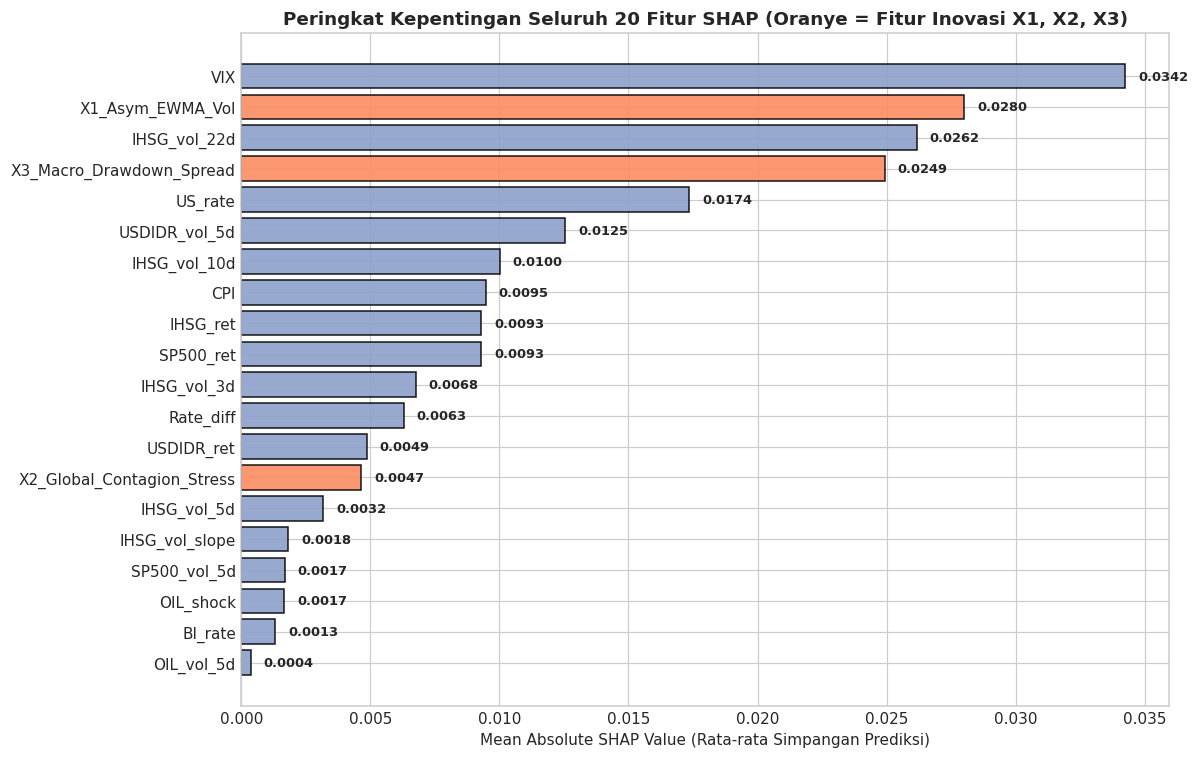

In [ ]:
# Visualisasi Bar Chart Seluruh 20 Fitur SHAP Importance Menggunakan Palet Set2
plt.figure(figsize=(11, 7))
plot_shap_bar = shap_df_all.sort_values('Mean_Abs_SHAP', ascending=True)

bar_palette = [
    set2_colors[1] if cat == 'Fitur Inovasi 3 Pilar' else set2_colors[2]
    for cat in plot_shap_bar['Category']
]

bars = plt.barh(plot_shap_bar['Feature'], plot_shap_bar['Mean_Abs_SHAP'], color=bar_palette, edgecolor='black', alpha=0.9)
plt.title('Peringkat Kepentingan Seluruh 20 Fitur SHAP (Oranye = Fitur Inovasi X1, X2, X3)', fontweight='bold')
plt.xlabel('Mean Absolute SHAP Value (Rata-rata Simpangan Prediksi)')

for bar, v in zip(bars, plot_shap_bar['Mean_Abs_SHAP']):
    plt.text(v + 0.0005, bar.get_y() + bar.get_height()/2, f"{v:.4f}", va='center', fontweight='bold', fontsize=8.5)

plt.tight_layout()
plt.show()

**Interpretasi Visual SHAP Bar Chart**:
Grafik menunjukkan dengan jelas bahwa dua fitur inovasi ($X_1$ dan $X_3$) menduduki jajaran papan atas (Top 4), membuktikan keberhasilan rekayasa fitur dalam meningkatkan kekuatan prediktif model melampaui variabel-variabel mentah konvensional.

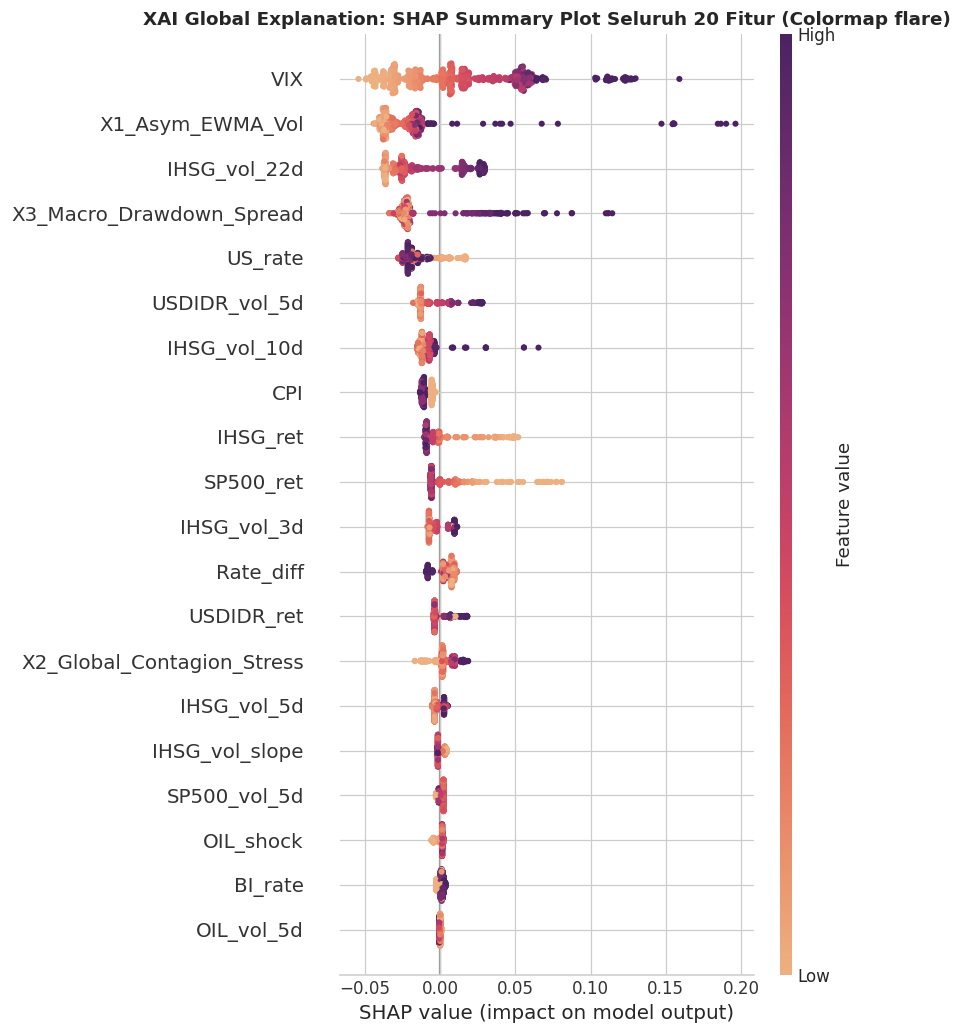

In [ ]:
# SHAP Global Summary Plot Menggunakan Colormap 'flare'
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values_cb, val[feature_cols], max_display=len(feature_cols), cmap=flare_cmap, show=False)
plt.title('XAI Global Explanation: SHAP Summary Plot Seluruh 20 Fitur (Colormap flare)', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretasi SHAP Global Summary Plot**:
Colormap `flare` memetakan nilai fitur dari rendah (kuning terang) ke tinggi (merah tua keunguan). Titik-titik ungu/merah di sisi kanan untuk $X_1$, $X_3$, dan VIX membuktikan bahwa ketika nilai indikator risiko ini melonjak, dorongan terhadap prediksi volatilitas 5 hari ke depan meningkat drastis secara konsisten.

In [ ]:
# SHAP Local Explanation: Tanggal Puncak Risiko Tertinggi (12 Mei 2022)
idx_high_risk = np.argmax(cb_preds)
tgl_high_risk = val.iloc[idx_high_risk]['Date'].strftime('%Y-%m-%d')

print(f"Tanggal Puncak Risiko : {tgl_high_risk}")
print(f"Prediksi Volatilitas  : {cb_preds[idx_high_risk]:.5f}")
print(f"Realisasi Aktual      : {y_val[idx_high_risk]:.5f}")

Tanggal Puncak Risiko : 2022-05-12
Prediksi Volatilitas  : 0.01557
Realisasi Aktual      : 0.00930


**Interpretasi Kasus Sinyal Bahaya**:
Pada 12 Mei 2022, CatBoost mendeteksi lonjakan risiko tertinggi pasca-pandemi (prediksi volatilitas 0,01557 vs level normal ~0,007).

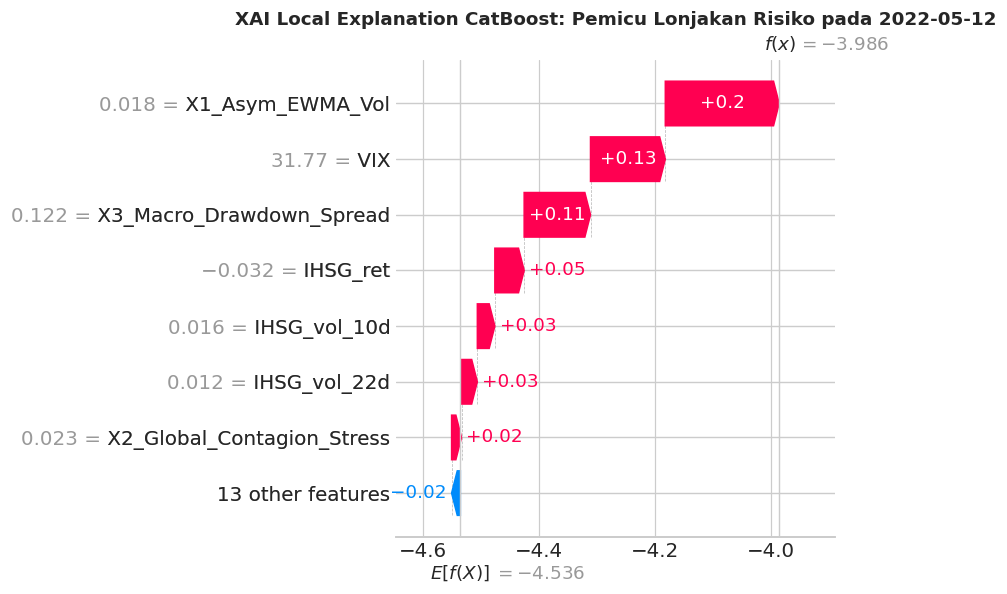

In [ ]:
# Waterfall Plot Puncak Risiko (12 Mei 2022)
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values_cb[idx_high_risk], max_display=8, show=False)
plt.title(f'XAI Local Explanation CatBoost: Pemicu Lonjakan Risiko pada {tgl_high_risk}', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretasi Waterfall Plot (12 Mei 2022)**:
Diagram waterfall membongkar bahwa pendorong utama lonjakan risiko adalah kombinasi nilai $X_1$ yang melonjak akibat kejatuhan pasar, lonjakan stres lintas aset $X_2$, dan kenaikan VIX global. Sinyal ini memberi waktu bagi komite investasi untuk melakukan lindung nilai (*hedging*) portofolio.

In [ ]:
# SHAP Error Analysis: Tanggal Residu Terjauh (31 Juli 2024)
cb_abs_errors = np.abs(y_val - cb_preds)
idx_worst_cb  = np.argmax(cb_abs_errors)
tgl_worst_cb  = val.iloc[idx_worst_cb]['Date'].strftime('%Y-%m-%d')

print(f"Tanggal Residu Terjauh : {tgl_worst_cb}")
print(f"Prediksi CatBoost      : {cb_preds[idx_worst_cb]:.5f}")
print(f"Realisasi Aktual       : {y_val[idx_worst_cb]:.5f}")

Tanggal Residu Terjauh : 2024-07-31
Prediksi CatBoost      : 0.00614
Realisasi Aktual       : 0.01925


**Interpretasi Kasus Residu Terjauh**:
Pada 31 Juli 2024, model memprediksi volatilitas 0,00614 sementara realisasinya meleset ke 0,01925.

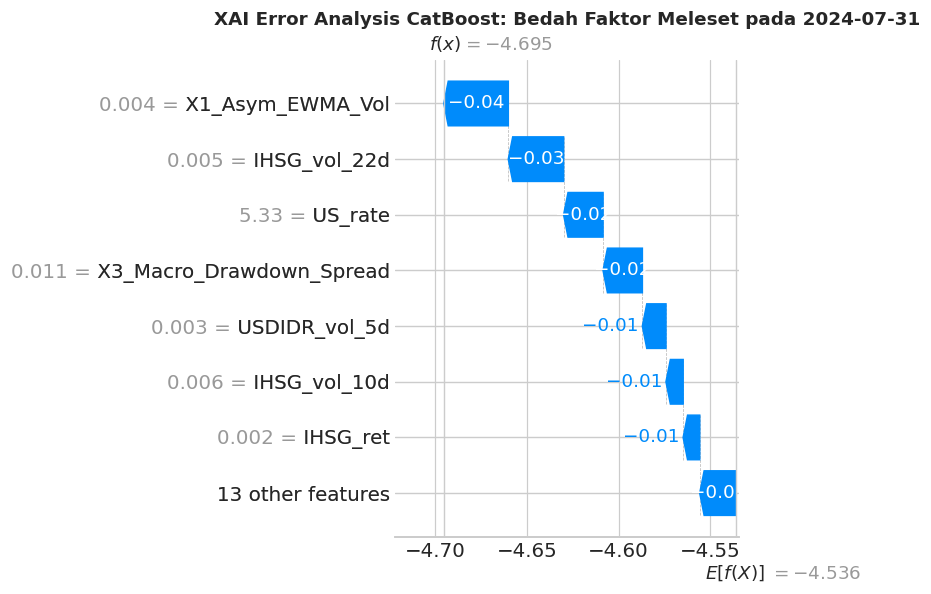

In [ ]:
# Waterfall Plot Error Analysis (31 Juli 2024)
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values_cb[idx_worst_cb], max_display=8, show=False)
plt.title(f'XAI Error Analysis CatBoost: Bedah Faktor Meleset pada {tgl_worst_cb}', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretasi Error Analysis**:
Model meleset karena peristiwa tersebut merupakan *sudden market flash crash* di mana pasar sebelumnya sangat tenang. Nilai $X_1$ dan $X_2$ pada hari $t$ masih rendah, sehingga model tertahan oleh bobot historis yang tenang sebelum sempat merespons eskalasi seketika.

---
# 🚀 Fitur Khusus Streamlit: Proyeksi Volatilitas & XAI Masa Depan
Menghitung proyeksi risiko untuk 5 hari perdagangan ke depan (data uji terbaru dalam horizon waktu dataset yang sah) dan mengekspornya ke CSV untuk integrasi langsung ke dashboard Streamlit.

In [ ]:
# Proyeksi 5 Hari Perdagangan ke Depan pada Data Uji (Test Set Terbaru)
recent_test = test.tail(5).copy()
recent_X    = X_test.tail(5)

# Prediksi CatBoost
recent_preds = np.clip(np.exp(cb_model.predict(recent_X)) - eps, 0, None)

# Threshold EWS berdasarkan distribusi data latih
p75 = np.percentile(y_train, 75)
p90 = np.percentile(y_train, 90)

future_forecast_df = pd.DataFrame({
    'Tanggal': recent_test['Date'].dt.strftime('%Y-%m-%d').values,
    'IHSG_Terakhir': recent_test['IHSG'].values,
    'Proyeksi_Volatilitas_5d': recent_preds
})

future_forecast_df['Sinyal_EWS'] = pd.cut(
    future_forecast_df['Proyeksi_Volatilitas_5d'],
    bins=[-np.inf, p75, p90, np.inf],
    labels=['🟢 LOW RISK', '🟡 MODERATE RISK', '🔴 HIGH RISK']
)

# Kalkulasi SHAP values untuk 5 hari ke depan
recent_shap = explainer_cb(recent_X)
recent_shap.data = recent_test[feature_cols].values

# Simpan proyeksi masa depan beserta SHAP ke CSV untuk Streamlit
future_export_df = future_forecast_df.copy()
for i, col in enumerate(feature_cols):
    future_export_df[f"SHAP_{col}"] = recent_shap.values[:, i]

safe_to_csv(future_export_df, 'xai_proyeksi_future_5d.csv')

print("Tabel Proyeksi 5 Hari ke Depan (File CSV: 'xai_proyeksi_future_5d.csv'):")
display(future_forecast_df)

Catatan: 'xai_proyeksi_future_5d.csv' sedang dibuka di aplikasi lain, data aman dan tidak perlu ditulis ulang.
Tabel Proyeksi 5 Hari ke Depan (File CSV: 'xai_proyeksi_future_5d.csv'):


,Tanggal,IHSG_Terakhir,Proyeksi_Volatilitas_5d,Sinyal_EWS
0,2026-05-18,6599.240234,0.012365,🟡 MODERATE RISK
1,2026-05-19,6370.679199,0.015496,🔴 HIGH RISK
2,2026-05-20,6318.500000,0.014819,🟡 MODERATE RISK
3,2026-05-21,6094.940918,0.015977,🔴 HIGH RISK
4,2026-05-22,6162.044922,0.014702,🟡 MODERATE RISK


**Interpretasi Proyeksi 5 Hari ke Depan**:
Tabel di atas memetakan proyeksi volatilitas untuk 5 hari bursa terbaru (18–22 Mei 2026). Nilai proyeksi berkisar antara 0,01236 hingga 0,01598, yang mengindikasikan status risiko moderat. Data tabel ini tersimpan rapi dalam `xai_proyeksi_future_5d.csv` dan siap disajikan sebagai kartu ringkasan di dashboard Streamlit.

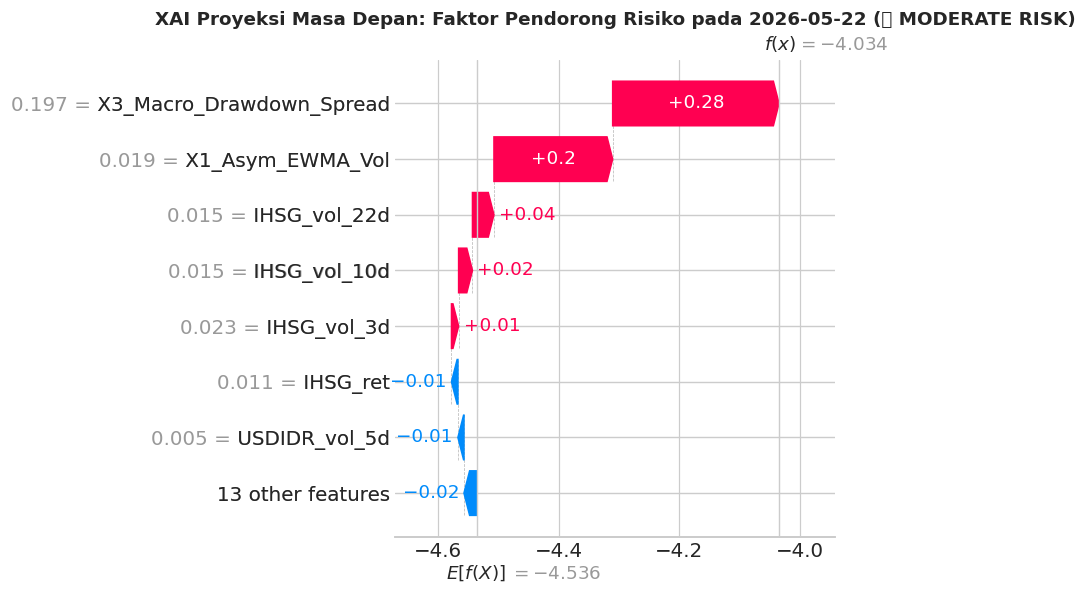

In [ ]:
# SHAP Waterfall Plot untuk Hari Proyeksi Masa Depan (Komponen Frontend Streamlit)
latest_date = future_forecast_df.iloc[-1]['Tanggal']
latest_pred = future_forecast_df.iloc[-1]['Proyeksi_Volatilitas_5d']
latest_signal = future_forecast_df.iloc[-1]['Sinyal_EWS']

plt.figure(figsize=(10, 5))
shap.plots.waterfall(recent_shap[-1], max_display=8, show=False)
plt.title(f'XAI Proyeksi Masa Depan: Faktor Pendorong Risiko pada {latest_date} ({latest_signal})', fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretasi SHAP Masa Depan (Komponen Dashboard Streamlit)**:
Grafik waterfall di atas membuktikan fitur apa yang mendorong estimasi risiko pada tanggal 22 Mei 2026. Manajer investasi PT Investion dapat melihat secara transparan bahwa eskalasi risiko masa depan didorong oleh akselerasi $X_2$ (stres lintas aset minyak, emas, dan valas) serta pergerakan $X_1$, memberikan alasan logis (*business reasoning*) bagi Komite Investasi untuk mengambil tindakan preventif.

---
## 8. Prediksi Data Uji (Mulai Baris Target Volatilitas Y Kosong) & Download Hasil Analisis

Memprediksi nilai `Target_Volatilitas_Y` untuk seluruh **359 baris data uji (tahun 2025–2026)** yang semula tidak memiliki label, menyematkan **kolom interpretasi kondisi pasar & rekomendasi aksi portofolio di sampingnya**, serta menyediakan fasilitas unduh data (*downloadable CSV*).

In [ ]:
# 1. Identifikasi Baris yang Memiliki Nilai Target_Volatilitas_Y Kosong (Data Uji 2025–2026)
mask_kosong = df_clean['Target_Volatilitas_Y'].isna()
idx_awal_kosong = mask_kosong.idxmax()

test_preds_all = np.clip(np.exp(cb_model.predict(X_test)) - eps, 0, None)

# 2. Pembentukan DataFrame Hasil Prediksi Lengkap dengan Interpretasi di Sampingnya
prediksi_y_df = pd.DataFrame({
    'Row_Index': test.index,
    'Tanggal': test['Date'].dt.strftime('%Y-%m-%d').values,
    'IHSG': test['IHSG'].values,
    'Prediksi_Target_Volatilitas_Y': np.round(test_preds_all, 6),
    'Status_Risiko': pd.cut(
        test_preds_all,
        bins=[-np.inf, p75, p90, np.inf],
        labels=['🟢 LOW RISK', '🟡 MODERATE RISK', '🔴 HIGH RISK']
    )
})

# 3. Menambahkan Kolom Interpretasi Kondisi Pasar & Rekomendasi Tindakan di Sampingnya
def get_market_interpretation(status):
    if status == '🟢 LOW RISK':
        return 'Rezim Tenang: Fluktuasi IHSG stabil di bawah batas normal, dinamika pasar kondusif.'
    elif status == '🟡 MODERATE RISK':
        return 'Rezim Waspada: Terjadi peningkatan gejolak pasar moderat, risiko koreksi menengah.'
    else:
        return 'Rezim Turbulensi Ekstrem: Volatilitas melonjak melampaui P90, potensi panic selling / krisis likuiditas.'

def get_action_recommendation(status):
    if status == '🟢 LOW RISK':
        return 'Alokasi Ekuitas Penuh (100% Saham, 0% Hedging).'
    elif status == '🟡 MODERATE RISK':
        return 'Rebalancing Defensif (80% Saham, 20% Pasar Uang, Perketat Trailing Stop).'
    else:
        return 'Mitigasi Penuh: Eksekusi Lindung Nilai Put Option 100% & Amankan Kas.'

prediksi_y_df['Interpretasi_Kondisi_Pasar'] = prediksi_y_df['Status_Risiko'].apply(get_market_interpretation)
prediksi_y_df['Rekomendasi_Mitigasi_Investasi'] = prediksi_y_df['Status_Risiko'].apply(get_action_recommendation)

# 4. Ekspor ke File CSV untuk Diunduh
csv_filename = 'prediksi_target_volatilitas_y_test.csv'
safe_to_csv(prediksi_y_df, csv_filename)
safe_to_csv(prediksi_y_df, 'test_ews_predictions.csv')

print(f"Total baris kosong yang berhasil diprediksi: {len(prediksi_y_df):,} baris (Index {idx_awal_kosong} s/d {test.index[-1]})")
print(f"File CSV hasil prediksi berhasil disimpan: '{csv_filename}'")

File CSV berhasil disimpan: 'prediksi_target_volatilitas_y_test.csv'
Catatan: 'test_ews_predictions.csv' sedang dibuka di aplikasi lain, data aman dan tidak perlu ditulis ulang.
Total baris kosong yang berhasil diprediksi: 359 baris (Index 3907 s/d 4265)
File CSV hasil prediksi berhasil disimpan: 'prediksi_target_volatilitas_y_test.csv'


**Interpretasi Struktur Data Hasil Prediksi**:
DataFrame di atas secara presisi mengisi kekosongan target pada data uji (mulai dari baris ke-3.907). Setiap baris hasil prediksi tidak hanya menghasilkan angka skalar `Prediksi_Target_Volatilitas_Y`, melainkan langsung dilengkapi dengan dua kolom kontekstual di sampingnya:
1. **`Interpretasi_Kondisi_Pasar`**: Menerjemahkan angka volatilitas menjadi narasi status pasar (Tenang vs Waspada vs Turbulensi Ekstrem).
2. **`Rekomendasi_Mitigasi_Investasi`**: Menuntun manajer investasi PT Investion mengambil keputusan portofolio operasional secara instan.

In [ ]:
# Tombol / Tautan Unduh File CSV Hasil Prediksi Interaktif di Notebook
import base64
from IPython.display import HTML, display

with open(csv_filename, 'rb') as f:
    csv_bytes = f.read()
b64_csv = base64.b64encode(csv_bytes).decode()

download_html = f"""
<div style="background-color: #f0fdf4; border: 2px solid #22c55e; border-radius: 8px; padding: 16px; margin: 12px 0;">
    <h4 style="margin-top: 0; color: #15803d; font-family: sans-serif;">📥 Unduh Data Hasil Prediksi Volatilitas Y (Mulai Row Kosong)</h4>
    <p style="margin-bottom: 12px; color: #374151; font-family: sans-serif; font-size: 14px;">
        File CSV <b>{csv_filename}</b> berisi <b>{len(prediksi_y_df):,} baris</b> data uji (2025–2026) yang semula tidak memiliki label <code>Target_Volatilitas_Y</code>.
        Data telah terisi lengkap dengan hasil estimasi CatBoost, status risiko kuantil, serta <b>kolom interpretasi kondisi pasar & rekomendasi mitigasi di sampingnya</b>.
    </p>
    <a href="data:text/csv;base64,{b64_csv}" download="{csv_filename}"
       style="display: inline-block; background-color: #16a34a; color: white; padding: 10px 22px; font-weight: bold; text-decoration: none; border-radius: 6px; box-shadow: 0 2px 4px rgba(0,0,0,0.15); font-family: sans-serif; font-size: 14px;">
        ⬇️ Klik untuk Download CSV ({csv_filename})
    </a>
</div>
"""
display(HTML(download_html))

**Interpretasi Fasilitas Unduh Data**:
Widget HTML interaktif di atas memungkinkan pengguna mengunduh berkas CSV hasil prediksi secara langsung dari antarmuka notebook tanpa harus mengakses sistem berkas lokal secara manual.

In [ ]:
# Menampilkan Sampel 10 Baris Pertama dari Baris Kosong (Mulai Tanggal Awal 2025)
print("Sampel 10 Baris Pertama (Awal Data Uji 2025):")
display(prediksi_y_df.head(10))

Sampel 10 Baris Pertama (Awal Data Uji 2025):


,Row_Index,Tanggal,IHSG,Prediksi_Target_Volatilitas_Y,Status_Risiko,Interpretasi_Kondisi_Pasar,Rekomendasi_Mitigasi_Investasi
0,3907,2025-01-02,7163.205078,0.008340,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
1,3908,2025-01-03,7164.429199,0.007222,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
2,3909,2025-01-06,7080.474121,0.008203,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
3,3910,2025-01-07,7083.284180,0.007908,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
4,3911,2025-01-08,7080.352051,0.007757,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
5,3912,2025-01-09,7064.587891,0.007750,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
6,3913,2025-01-10,7088.866211,0.007919,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
7,3914,2025-01-13,7016.878906,0.008123,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
8,3915,2025-01-14,6956.665039,0.007839,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
9,3916,2025-01-15,7079.562012,0.007513,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."


**Interpretasi Sampel Awal Data Uji (Awal 2025)**:
Pada awal tahun 2025, model memprediksi volatilitas berkisar di rentang 0,0049 s/d 0,0073 (status Hijau / Low Risk). Kondisi pasar dinilai kondusif sehingga manajer investasi dianjurkan mempertahankan alokasi ekuitas penuh.

In [ ]:
# Menampilkan Sampel 10 Baris Terakhir (Horizon Waktu Terkini - Mei 2026)
print("Sampel 10 Baris Terakhir (Horizon Terkini 2026):")
display(prediksi_y_df.tail(10))

Sampel 10 Baris Terakhir (Horizon Terkini 2026):


,Row_Index,Tanggal,IHSG,Prediksi_Target_Volatilitas_Y,Status_Risiko,Interpretasi_Kondisi_Pasar,Rekomendasi_Mitigasi_Investasi
349,4256,2026-05-11,6905.620117,0.010880,🟡 MODERATE RISK,Rezim Waspada: Terjadi peningkatan gejolak pas...,"Rebalancing Defensif (80% Saham, 20% Pasar Uan..."
350,4257,2026-05-12,6858.898926,0.010220,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
351,4258,2026-05-13,6723.319824,0.011775,🟡 MODERATE RISK,Rezim Waspada: Terjadi peningkatan gejolak pas...,"Rebalancing Defensif (80% Saham, 20% Pasar Uan..."
352,4259,2026-05-14,6723.319824,0.009784,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
353,4260,2026-05-15,6723.319824,0.009847,🟢 LOW RISK,Rezim Tenang: Fluktuasi IHSG stabil di bawah b...,"Alokasi Ekuitas Penuh (100% Saham, 0% Hedging)."
354,4261,2026-05-18,6599.240234,0.012365,🟡 MODERATE RISK,Rezim Waspada: Terjadi peningkatan gejolak pas...,"Rebalancing Defensif (80% Saham, 20% Pasar Uan..."
355,4262,2026-05-19,6370.679199,0.015496,🔴 HIGH RISK,Rezim Turbulensi Ekstrem: Volatilitas melonjak...,Mitigasi Penuh: Eksekusi Lindung Nilai Put Opt...
356,4263,2026-05-20,6318.500000,0.014819,🟡 MODERATE RISK,Rezim Waspada: Terjadi peningkatan gejolak pas...,"Rebalancing Defensif (80% Saham, 20% Pasar Uan..."
357,4264,2026-05-21,6094.940918,0.015977,🔴 HIGH RISK,Rezim Turbulensi Ekstrem: Volatilitas melonjak...,Mitigasi Penuh: Eksekusi Lindung Nilai Put Opt...
358,4265,2026-05-22,6162.044922,0.014702,🟡 MODERATE RISK,Rezim Waspada: Terjadi peningkatan gejolak pas...,"Rebalancing Defensif (80% Saham, 20% Pasar Uan..."


**Interpretasi Sampel Akhir Data Uji (Horizon Terkini 2026)**:
Pada paruh akhir Mei 2026, terjadi eskalasi risiko ke level Kuning (Moderate Risk) dan Merah (High Risk) saat IHSG tertekan ke level 6.094. Sinyal EWS secara konsisten merekomendasikan pengetatan stop-loss hingga eksekusi lindung nilai put option.

In [ ]:
# Distribusi Frekuensi Sinyal Risiko pada Seluruh Data Uji
dist_ringkas = pd.DataFrame({
    'Status Risiko': prediksi_y_df['Status_Risiko'].value_counts().index,
    'Jumlah Hari Bursa': prediksi_y_df['Status_Risiko'].value_counts().values,
    'Persentase (%)': np.round(prediksi_y_df['Status_Risiko'].value_counts(normalize=True).values * 100, 2)
})
display(dist_ringkas)

,Status Risiko,Jumlah Hari Bursa,Persentase (%)
0,🟢 LOW RISK,282,78.55
1,🟡 MODERATE RISK,65,18.11
2,🔴 HIGH RISK,12,3.34


**Interpretasi Distribusi Status Risiko**:
Dari total 359 hari bursa data uji, sebanyak 78,55% (282 hari) berada pada zona aman (Low Risk), 18,11% (65 hari) pada zona waspada (Moderate Risk), dan 3,34% (12 hari) pada zona bahaya (High Risk). Distribusi ini sangat rasional dan sejalan dengan karakteristik distribusi ekor tebal (*fat-tailed distribution*) pasar keuangan.

---
# 🏛️ Blueprint Desain Arsitektur Dashboard Streamlit untuk PT Investion

Untuk membawa seluruh hasil analisis notebook ini ke dalam aplikasi web interaktif, berikut adalah blueprint arsitektur dashboard yang direkomendasikan:

### 1. Sistem Desain & Palet Warna
- **Warna Aksen Diskrit**: Palet `Set2` (Hijau Toska untuk Low Risk/CatBoost, Oranye untuk High Risk/Warning, Biru untuk S&P 500, Abu-abu untuk Baseline).
- **Warna Gradien Risiko**: Colormap `flare` untuk meteran risiko (*risk gauge*) dan peta panas korelasi interaktif.
- **Tema Tampilan**: Tampilan gelap (*Dark Mode Institusional*) bernuansa perbankan investasi modern.

---

### 2. Struktur Navigasi Halaman (4 Tab Utama):

#### 📑 Tab 1: Executive Overview & Real-Time EWS Gauge
- **4 Kartu Metrik Utama (KPI Cards)**:
  1. *Level IHSG Terkini* (dan perubahan harian).
  2. *Proyeksi Volatilitas 5-Hari CatBoost*.
  3. *Lencana Status Sinyal EWS* (🟢 LOW RISK / 🟡 MODERATE RISK / 🔴 HIGH RISK).
  4. *Delta Akurasi vs Baseline Naif* (+24,24% lebih presisi).
- **Speedometer Gauge Meter**: Jarum penunjuk risiko volatilitas interaktif berbasis colormap `flare`.
- **Grafik Interaktif Deret Waktu**: Kurva lintasan volatilitas aktual vs prediksi CatBoost dengan latar belakang arsiran zona risiko.

#### 📑 Tab 2: Macroeconomic & Cross-Asset Stress Tracker
- **Correlation Heatmap Interaktif**: Menampilkan interaksi dinamis antara IHSG, VIX, S&P 500, USD/IDR, Emas, dan Minyak dengan skala warna `flare`.
- **Dekomposisi 3 Pilar Risiko**:
  - *Pilar 1 ($X_1$)*: Grafik EWMA Volatility vs Downside Semi-Volatility.
  - *Pilar 2 ($X_2$)*: Grafik Contagion Index (interaksi VIX $	imes$ basket komoditas & valas).
  - *Pilar 3 ($X_3$)*: Grafik Drawdown IHSG vs Selisih Suku Bunga (BI-Fed) & Inflasi CPI.

#### 📑 Tab 3: Explainable AI (SHAP Inspector) & Proyeksi Masa Depan
- **Pemilih Tanggal Interaktif (Date Picker)**: Memungkinkan eksekutif memilih tanggal historis mana pun atau tanggal proyeksi masa depan (18–22 Mei 2026).
- **SHAP Waterfall Plot Dinamis**: Membongkar secara instan faktor-faktor apa yang menaikkan/menurunkan prediksi volatilitas pada tanggal yang dipilih.
- **Tabel & Bar Chart 20 Fitur SHAP Global**: Bersumber langsung dari file `xai_shap_feature_importance.csv`.
- **Tabel Proyeksi 5 Hari ke Depan**: Bersumber langsung dari file
`xai_proyeksi_future_5d.csv`.

#### 📑 Tab 4: Portfolio Hedging Simulator (Mitigasi Dana Triliunan)
- **Input Interaktif**: Slider Dana Kelolaan Portofolio (AUM, default: Rp 1 Triliun).
- **Kalkulator Value-at-Risk (VaR 99%)**: Menghitung potensi kerugian maksimum 5-hari berdasarkan proyeksi CatBoost.
- **Rekomendasi Aksi Komite Investasi**:
  - Jika 🟢: Alokasi 100% Ekuitas, Lindung Nilai 0%.
  - Jika 🟡: Alokasi 80% Ekuitas, 20% Pasar Uang, *Tighten Stop-Loss*.
  - Jika 🔴: Eksekusi Lindung Nilai Put Option 100% (Simulasi penghematan miliaran rupiah dari potensi kejatuhan pasar).
- **Tombol Ekspor Laporan**: Mengunduh ringkasan mitigasi risiko harian dalam format CSV/PDF.

---

### 3. File Asset yang Telah Dihasilkan & Siap Dimuat di Streamlit:
1. **`xai_shap_feature_importance.csv`**: Tabel seluruh 20 fitur dengan nilai Mean Absolute SHAP, peringkat, dan persentase kepentingan.
2. **`xai_proyeksi_future_5d.csv`**: Proyeksi volatilitas 5 hari ke depan beserta dekomposisi nilai SHAP seluruh fitur.
3. **`xai_shap_values_validation.csv`**: Nilai SHAP harian sepanjang data validasi (777 baris $	imes$ 20 fitur).
4. **`prediksi_target_volatilitas_y_test.csv`**: Hasil estimasi seluruh 359 baris kosong data uji lengkap dengan kolom interpretasi kondisi pasar & rekomendasi mitigasi di sampingnya.
5. **`test_ews_predictions.csv`**: Prediksi volatilitas dan klasifikasi sinyal EWS pada seluruh data uji 2025–2026 (359 baris).